### Taylor Stafford's Final Project-- DATA 720

##### The following projects is hoping to answer the question of Whether or not Sprint Weekends effect drivers’ performance in the final race. 
A conventional weekend contains 3 Free Practice Session and 1 race. A sprint weekend contains 1 Free Practice session and 2 races. This is significant for F1 as a broadcaster and ticket seller as more people watch and enjoy sprint races rather than more practice sessions. Having more eyes on sessions means more money and more sponsors on those events. The teams and drivers speak out in interviews that they prefer the practice session as the sprints don't serve much of a purpose to them and hurt the performance in the Main race. <br> I am hoping in investigate these claim and determine if sprint race causes impact.

In [1]:
import pandas as pd
import numpy as np
##For Data manipulation and cleaning
import matplotlib.pyplot as plt
import seaborn as sns
##For Visualization
import scipy.stats as stats
from scipy.stats import shapiro
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import statsmodels.formula.api as smf
##For Statistics
import fastf1
import os

Above are the Python Libraries I plan to use though out this project.

In [2]:
os.makedirs("f1_cache", exist_ok=True)
##Create cache as temporary storage for data, if it doesn't exist
fastf1.Cache.enable_cache('f1_cache')
##Use cache for faster data useage

Above is the cache creation and use of that cache for the data in this project to be stored/ called upon.

In [3]:
def load_schedule(year):
    '''Function to Load F1 Schedule for a particular year
    Returning a Dataframe with FP1, FP2, FP3, Qualifing, Sprint, Race data for each round in a year
    load_schedule(year) '''
    schedule = fastf1.get_event_schedule(year)
    ##Get Event Schedule and store it
    for _, event in schedule.iterrows():
    ##Iterate over events
        round_num = event['RoundNumber']
        ##Grab Round Number
        sessions = ['FP1', 'FP2', 'FP3', 'Q', 'Sprint', 'R']
        ##List of standard session types
        for session_name in sessions:
        ##For each wanted session type
            try:
                session = fastf1.get_session(year, round_num, session_name)
                session.load()
                ##Load Session type
                print(f"Loaded {session_name} for round {round_num}: {event['OfficialEventName']}")
            except Exception as e:
                print(f"Skipping {session_name} for round {round_num} due to: {e}")
                ##If missing or failed session loading
    return schedule

This Function, load_schedule, is built and designed to pull a Formula schedule for a particular year using the FastF1 library into a data frame for data manipulation and screening.

In [4]:
def load_fp(year, schedule):
    '''Function to Load Free Practice session for a particular year and schedule
    Returning a Dataframe with FP1, FP2, FP3, results for each round in a year
    load_fp(year, schedule) '''
    records = []
    ##Empty list for storage
    schedule_df = pd.DataFrame(schedule)
    ##Store Schedule as dataframe just in case
    session_names = ['FP1', 'FP2', 'FP3']
    ##Store Seesion names we want to grab

    for _, race in schedule_df.iterrows():
    ##For each round
        round_num = int(race['RoundNumber'])
        ##Grab round number as int type
        for session_name in session_names:
        ##For each session type we want
            try:
                session = fastf1.get_session(year, round_num, session_name)
                ##Get Session from library
                session.load(laps=True)
                ##Load
                laps = session.laps
                ##Store Laps
                print(f"Session {session_name} laps loaded: {len(laps)}")
                print(f"Columns in laps: {laps.columns.tolist()}")
                ##Sanity checks for loading
                valid_laps = laps[(laps['Deleted'] == False) & (laps['IsAccurate'] == True)]
                ##Remove non-Valid laps from data 
                print(f"Valid laps count: {len(valid_laps)}")
                ##Sanity Check
                if valid_laps.empty:
                    continue
                    ##In Case all laps are invalid contine
                    
                fastest_laps = valid_laps.groupby('DriverNumber').apply(lambda x: x.loc[x['LapTime'].idxmin()][valid_laps.columns])
                ##Store fastest laps by divernumber
                lap_counts = valid_laps.groupby('DriverNumber').size()
                ##Count Valid laps
                for driver_number, fastest_lap in fastest_laps.iterrows():
                ##For each driver's fastest laps in a session grab and store following information
                    records.append({
                        'Year': year,
                        'Round': round_num,
                        'Session': session_name,
                        'DriverNumber': fastest_lap['DriverNumber'],
                        'FastestLapTime': fastest_lap['LapTime'].total_seconds() if pd.notnull(fastest_lap['LapTime']) else None,
                        'TotalLaps': lap_counts[driver_number]})
                    
            except Exception as e:
            ##In Case of problems or missing/ non wanted sessions
                print(f"Skipping {session_name} round {round_num} due to error: {e}")
                continue
                
    fp_session_df = pd.DataFrame(records)
    ##Store as Dataframe and return
    return fp_session_df

This Function, load_fp, is built and designed to pull every Free Practice session from a F1 schedule and year into a data frame for data manipulation and screening.

In [5]:
def load_race(year, schedule):
    '''Function to Load Race sessions for a particular year and schedule
    Returning a Dataframe with results for each driver 
    load_race(year, schedule) '''
    records = []
    ##Empty list for storage
    schedule_df = pd.DataFrame(schedule)
    ##Store Schedule as dataframe just in case
    for _, race in schedule_df.iterrows():
    ##For each round
        round_num = int(race['RoundNumber'])
        ##Grab round number as int type
        try:
            session = fastf1.get_session(year, round_num, 'R')
            session.load()
            ##Get Seesion 'R' (Race) from library
            for _, row in session.results.iterrows():
            ##For Each row in race session grab and store following information
                records.append({
                    'Year': year,
                    'Round': round_num,
                    'DriverNumber': row['DriverNumber'],
                    'RacePosition': row['Position'],})
        except Exception as e:
        ##In Case of problems or missing
            print(f"Skipping race results for round {round_num}: {e}")
    race_df = pd.DataFrame(records)
    ##Store as Dataframe and return
    return race_df

This Function, load_race, is built and designed to pull every Race session from a F1 schedule and year into a data frame for data manipulation and screening.

In [6]:
year = 2024
##Wanted Year

Here we store the wanted year into a variable for calling upon when needed.

In [7]:
schedule_24 = load_schedule(year)
##Load Schedule

core           INFO 	Loading data for Bahrain Grand Prix - Practice 1 [v3.6.1]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info


Skipping FP1 for round 0 due to: Cannot get testing event by round number!
Skipping FP2 for round 0 due to: Cannot get testing event by round number!
Skipping FP3 for round 0 due to: Cannot get testing event by round number!
Skipping Q for round 0 due to: Cannot get testing event by round number!
Skipping Sprint for round 0 due to: Cannot get testing event by round number!
Skipping R for round 0 due to: Cannot get testing event by round number!


req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
core        WARNING 	Fixed incorrect tyre stint information for driver '23'
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['1', '2', '3', '4', '10', '11', '14', '16', '18', '20', '22', '23', '24', '27', '31', '44', '55', '63', '77', '81']
core           INFO 	Loading data for Bahrain Grand Prix - Practice 2 [v3.6.1]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached

Loaded FP1 for round 1: FORMULA 1 GULF AIR BAHRAIN GRAND PRIX 2024


req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['1', '2', '3', '4', '10', '11', '14', '16', '18', '20', '22', '23', '24', '27', '31', '44', '55', '63', '77', '81']
core           INFO 	Loading data for Bahrain Grand Prix - Practice 3 [v3.6.1]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...


Loaded FP2 for round 1: FORMULA 1 GULF AIR BAHRAIN GRAND PRIX 2024


... (220 outputs left out)

req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['4', '81', '55', '27', '1', '10', '63', '14', '77', '11', '22', '30', '18', '16', '20', '23', '24', '44', '43', '61']
core           INFO 	Loading data for Abu Dhabi Grand Prix - Race [v3.6.1]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_c

Loaded Q for round 24: FORMULA 1 ETIHAD AIRWAYS ABU DHABI GRAND PRIX 2024
Skipping Sprint for round 24 due to: Session type 'Sprint' does not exist for this event


req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['4', '55', '16', '44', '63', '1', '10', '27', '14', '81', '23', '22', '24', '18', '61', '20', '30', '77', '43', '11']


Loaded R for round 24: FORMULA 1 ETIHAD AIRWAYS ABU DHABI GRAND PRIX 2024


We load the schedule for the 2024 formula 1 schedule.

In [8]:
fp_24 = load_fp(year, schedule_24)
##Load Free Practices

core           INFO 	Loading data for Bahrain Grand Prix - Practice 1 [v3.6.1]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...


Skipping FP1 round 0 due to error: Cannot get testing event by round number!
Skipping FP2 round 0 due to error: Cannot get testing event by round number!
Skipping FP3 round 0 due to error: Cannot get testing event by round number!


core        WARNING 	Fixed incorrect tyre stint information for driver '23'
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['1', '2', '3', '4', '10', '11', '14', '16', '18', '20', '22', '23', '24', '27', '31', '44', '55', '63', '77', '81']
/tmp/ipykernel_794266/1904171212.py:36: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  fastest_laps = valid_laps.groupby('DriverNumber').apply(lambda x: x.loc[x['LapTime'].idxmin()][valid_laps.columns])
core           INFO 	Loadi

Session FP1 laps loaded: 449
Columns in laps: ['Time', 'Driver', 'DriverNumber', 'LapTime', 'LapNumber', 'Stint', 'PitOutTime', 'PitInTime', 'Sector1Time', 'Sector2Time', 'Sector3Time', 'Sector1SessionTime', 'Sector2SessionTime', 'Sector3SessionTime', 'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST', 'IsPersonalBest', 'Compound', 'TyreLife', 'FreshTyre', 'Team', 'LapStartTime', 'LapStartDate', 'TrackStatus', 'Position', 'Deleted', 'DeletedReason', 'FastF1Generated', 'IsAccurate']
Valid laps count: 284


req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['1', '2', '3', '4', '10', '11', '14', '16', '18', '20', '22', '23', '24', '27', '31', '44', '55', '63', '77', '81']
/tmp/ipykernel_794266/1904171212.py:36: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  fastest_laps = valid_laps.groupby('DriverNumber').apply(lambda x: x.loc[x['LapTime'].idxmin()][valid_laps.columns])
core           INFO 	Loading data for Bahrain Grand Prix - Practice 3 [v3.6.1]
req            INFO 	Us

Session FP2 laps loaded: 511
Columns in laps: ['Time', 'Driver', 'DriverNumber', 'LapTime', 'LapNumber', 'Stint', 'PitOutTime', 'PitInTime', 'Sector1Time', 'Sector2Time', 'Sector3Time', 'Sector1SessionTime', 'Sector2SessionTime', 'Sector3SessionTime', 'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST', 'IsPersonalBest', 'Compound', 'TyreLife', 'FreshTyre', 'Team', 'LapStartTime', 'LapStartDate', 'TrackStatus', 'Position', 'Deleted', 'DeletedReason', 'FastF1Generated', 'IsAccurate']
Valid laps count: 350


... (113 outputs left out)

Session FP2 laps loaded: 507
Columns in laps: ['Time', 'Driver', 'DriverNumber', 'LapTime', 'LapNumber', 'Stint', 'PitOutTime', 'PitInTime', 'Sector1Time', 'Sector2Time', 'Sector3Time', 'Sector1SessionTime', 'Sector2SessionTime', 'Sector3SessionTime', 'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST', 'IsPersonalBest', 'Compound', 'TyreLife', 'FreshTyre', 'Team', 'LapStartTime', 'LapStartDate', 'TrackStatus', 'Position', 'Deleted', 'DeletedReason', 'FastF1Generated', 'IsAccurate']
Valid laps count: 312


req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['1', '4', '10', '11', '14', '16', '18', '20', '22', '23', '24', '27', '30', '43', '44', '55', '61', '63', '77', '81']


Session FP3 laps loaded: 342
Columns in laps: ['Time', 'Driver', 'DriverNumber', 'LapTime', 'LapNumber', 'Stint', 'PitOutTime', 'PitInTime', 'Sector1Time', 'Sector2Time', 'Sector3Time', 'Sector1SessionTime', 'Sector2SessionTime', 'Sector3SessionTime', 'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST', 'IsPersonalBest', 'Compound', 'TyreLife', 'FreshTyre', 'Team', 'LapStartTime', 'LapStartDate', 'TrackStatus', 'Position', 'Deleted', 'DeletedReason', 'FastF1Generated', 'IsAccurate']
Valid laps count: 164


/tmp/ipykernel_794266/1904171212.py:36: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  fastest_laps = valid_laps.groupby('DriverNumber').apply(lambda x: x.loc[x['LapTime'].idxmin()][valid_laps.columns])


We load the Free Practice data for the 2024 formula 1 schedule.

In [9]:
race_24 = load_race(year, schedule_24)
##Load Races

core           INFO 	Loading data for Bahrain Grand Prix - Race [v3.6.1]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...


Skipping race results for round 0: Cannot get testing event by round number!


req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['1', '11', '55', '16', '63', '4', '44', '81', '14', '18', '24', '20', '3', '22', '23', '27', '31', '10', '77', '2']
core           INFO 	Loading data for Saudi Arabian Grand Prix - Race [v3.6.1]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for car_data
req 

We load the Race data for the 2024 formula 1 schedule.

In [10]:
schedule_24.head()

,RoundNumber,Country,Location,OfficialEventName,EventDate,EventName,EventFormat,Session1,Session1Date,Session1DateUtc,...,Session3,Session3Date,Session3DateUtc,Session4,Session4Date,Session4DateUtc,Session5,Session5Date,Session5DateUtc,F1ApiSupport
0,0,Bahrain,Sakhir,FORMULA 1 ARAMCO PRE-SEASON TESTING 2024,2024-02-23,Pre-Season Testing,testing,Practice 1,2024-02-21 10:00:00+03:00,2024-02-21 07:00:00,...,Practice 3,2024-02-23 10:00:00+03:00,2024-02-23 07:00:00,None,NaT,NaT,None,NaT,NaT,True
1,1,Bahrain,Sakhir,FORMULA 1 GULF AIR BAHRAIN GRAND PRIX 2024,2024-03-02,Bahrain Grand Prix,conventional,Practice 1,2024-02-29 14:30:00+03:00,2024-02-29 11:30:00,...,Practice 3,2024-03-01 15:30:00+03:00,2024-03-01 12:30:00,Qualifying,2024-03-01 19:00:00+03:00,2024-03-01 16:00:00,Race,2024-03-02 18:00:00+03:00,2024-03-02 15:00:00,True
2,2,Saudi Arabia,Jeddah,FORMULA 1 STC SAUDI ARABIAN GRAND PRIX 2024,2024-03-09,Saudi Arabian Grand Prix,conventional,Practice 1,2024-03-07 16:30:00+03:00,2024-03-07 13:30:00,...,Practice 3,2024-03-08 16:30:00+03:00,2024-03-08 13:30:00,Qualifying,2024-03-08 20:00:00+03:00,2024-03-08 17:00:00,Race,2024-03-09 20:00:00+03:00,2024-03-09 17:00:00,True
3,3,Australia,Melbourne,FORMULA 1 ROLEX AUSTRALIAN GRAND PRIX 2024,2024-03-24,Australian Grand Prix,conventional,Practice 1,2024-03-22 12:30:00+11:00,2024-03-22 01:30:00,...,Practice 3,2024-03-23 12:30:00+11:00,2024-03-23 01:30:00,Qualifying,2024-03-23 16:00:00+11:00,2024-03-23 05:00:00,Race,2024-03-24 15:00:00+11:00,2024-03-24 04:00:00,True
4,4,Japan,Suzuka,FORMULA 1 MSC CRUISES JAPANESE GRAND PRIX 2024,2024-04-07,Japanese Grand Prix,conventional,Practice 1,2024-04-05 11:30:00+09:00,2024-04-05 02:30:00,...,Practice 3,2024-04-06 11:30:00+09:00,2024-04-06 02:30:00,Qualifying,2024-04-06 15:00:00+09:00,2024-04-06 06:00:00,Race,2024-04-07 14:00:00+09:00,2024-04-07 05:00:00,True


Check the Head of the Schedule to ensure proper loading. 

In [11]:
fp_24.head()

,Year,Round,Session,DriverNumber,FastestLapTime,TotalLaps
0,2024,1,FP1,1,93.238,12
1,2024,1,FP1,10,95.144,16
2,2024,1,FP1,11,93.413,13
3,2024,1,FP1,14,93.193,11
4,2024,1,FP1,16,93.268,15


Check the Head of the Free Practice DataFrame to ensure proper loading.

In [12]:
race_24.head()

,Year,Round,DriverNumber,RacePosition
0,2024,1,1,1.0
1,2024,1,11,2.0
2,2024,1,55,3.0
3,2024,1,16,4.0
4,2024,1,63,5.0


Check the Head of the Race DataFrame to ensure proper loading.

In [13]:
pivot_df = fp_24.pivot_table(
    index=['Round', 'DriverNumber'],
    columns='Session',
    values=['FastestLapTime', 'TotalLaps'] )
##Oragnize Data for Readability
pivot_df.columns = ['_'.join(col).lower() for col in pivot_df.columns]
##Flatten multi-level columns:
pivot_df = pivot_df.reset_index()
##Reset index
pivot_df.head()

,Round,DriverNumber,fastestlaptime_fp1,fastestlaptime_fp2,fastestlaptime_fp3,totallaps_fp1,totallaps_fp2,totallaps_fp3
0,1,1,93.238,90.851,91.062,12.0,18.0,9.0
1,1,10,95.144,91.951,92.382,16.0,18.0,8.0
2,1,11,93.413,91.115,91.248,13.0,18.0,7.0
3,1,14,93.193,90.660,90.965,11.0,14.0,11.0
4,1,16,93.268,91.113,91.094,15.0,18.0,9.0


Here I have pivoted the Data frame grouped on Round and Driver Number to flatten Session into Fp1/FP2/FP3 columns with fast lap and total laps for each.

In [14]:
rename_dict = {
    'fastestlaptime_fp1': 'FP1',
    'fastestlaptime_fp2': 'FP2',
    'fastestlaptime_fp3': 'FP3',
    'totallaps_fp1': 'LapTotal_FP1',
    'totallaps_fp2': 'LapTotal_FP2',
    'totallaps_fp3': 'LapTotal_FP3'}
pivot_df.rename(columns=rename_dict, inplace=True)
##Rename colums for ease of use

Here I have renamed several of the columns to easier to call names that ease readability.

In [15]:
session_cols = ['FP1', 'FP2', 'FP3']  # Adjust if needed
##Wanted Sessions
pivot_df['Best_LapTime'] = pivot_df[session_cols].min(axis=1)
##Grab fastest Lap over all sessions
total_lap_cols = ['LapTotal_FP1', 'LapTotal_FP2', 'LapTotal_FP3'] 
# Calculate total laps across all sessions
pivot_df['Total_Laps'] = pivot_df[total_lap_cols].sum(axis=1)
##Add Column for Total Laps
pivot_df['SessionParticipation'] = pivot_df[session_cols].count(axis=1)
##Add Column for Session participation
pivot_df.head()

,Round,DriverNumber,FP1,FP2,FP3,LapTotal_FP1,LapTotal_FP2,LapTotal_FP3,Best_LapTime,Total_Laps,SessionParticipation
0,1,1,93.238,90.851,91.062,12.0,18.0,9.0,90.851,39.0,3
1,1,10,95.144,91.951,92.382,16.0,18.0,8.0,91.951,42.0,3
2,1,11,93.413,91.115,91.248,13.0,18.0,7.0,91.115,38.0,3
3,1,14,93.193,90.660,90.965,11.0,14.0,11.0,90.660,36.0,3
4,1,16,93.268,91.113,91.094,15.0,18.0,9.0,91.094,42.0,3


Here I find that best overall lap time from the 3 free practice sessions. I also total the laps from all 3 sessions. I get session participation for each driver.

In [16]:
col=['Round', 'DriverNumber','SessionParticipation', 'FP1', 'FP2', 'FP3', 'LapTotal_FP1', 'LapTotal_FP2', 'LapTotal_FP3', 'Best_LapTime', 'Total_Laps']
pivot_2=pivot_df[col]
##ReOrder Columns

Here I do some simple reordering of columns for readability.

In [17]:
f1_2024 = pd.merge(pivot_2, race_24[['Round', 'DriverNumber', 'RacePosition']], on= ['Round', 'DriverNumber'], how='inner')
##Merge Practice+Race data on inner to keeps only matching columns rempoving fp1 only drivers

I then merge with the Free Practice Data frame that I made more for my use with the Race data using the inner property to only get drivers that have race results.

In [18]:
f1_2024 = f1_2024.merge(schedule_24[['RoundNumber', 'EventFormat']], left_on='Round',right_on='RoundNumber',how='left')
f1_2024 = f1_2024.drop(columns=['RoundNumber'])
##Merge f1_2024 with Schedule to get eventformat column and drop extra Round number
cols = f1_2024.columns.tolist()
##Get column headers
cols.remove('EventFormat')
##Remove EventFormat
driver_idx = cols.index('DriverNumber')
##Get Index of DriverNumber
cols.insert(driver_idx, 'EventFormat')
##INsert EventFormat infront of DriverNumber
f1_2024 = f1_2024[cols]
##Reorder columns
f1_2024['DriverNumber'] = f1_2024['DriverNumber'].astype(int)
##Change Driver Number to Integer

I then merge onto my data frame the event format on round number, remove that extra round number. I then transfer columns to a list to reorder event format and finally change driver number to and integer for ease of use.

In [19]:
f1_2024.head()

,Round,EventFormat,DriverNumber,SessionParticipation,FP1,FP2,FP3,LapTotal_FP1,LapTotal_FP2,LapTotal_FP3,Best_LapTime,Total_Laps,RacePosition
0,1,conventional,1,3,93.238,90.851,91.062,12.0,18.0,9.0,90.851,39.0,1.0
1,1,conventional,10,3,95.144,91.951,92.382,16.0,18.0,8.0,91.951,42.0,18.0
2,1,conventional,11,3,93.413,91.115,91.248,13.0,18.0,7.0,91.115,38.0,2.0
3,1,conventional,14,3,93.193,90.660,90.965,11.0,14.0,11.0,90.660,36.0,9.0
4,1,conventional,16,3,93.268,91.113,91.094,15.0,18.0,9.0,91.094,42.0,4.0


I then check my dataframe

In [20]:
def practice_position(df, round_col, driver_col, laptime_col, laps_col):
    '''Function to make a perdiction from Dataframe, round number, driver number, best_laptime, and total laps
       practice_position(df, round_col, driver_col, laptime_col, laps_col)
       Take Best laptime and total laps and assign weights (0.7 for time and 0.3 for count) to measure how well a driver did in practice
       Returns a dataframe with PracticePosition column'''
    final_df = []
    ##Empty liost for storage
    grouped = df.groupby(round_col)
    ##Group on Round
    for round_name, group in grouped:
    ##For each group/ Round
        group_copy = group.copy()
        ##Copy dataframe for use
        # Normalize lap time and laps within the round
        normal_lap = (group_copy[laptime_col].max() - group_copy[laptime_col]) / (group_copy[laptime_col].max() - group_copy[laptime_col].min())
        ##Takes max and min laptime to find range of laps in a round
        ##Calculates how well a lap is compared to that max lap time
        #So that a higher score closer to 1 is a faster lap and a 0 is a slower lap
        normal_count = (group_copy[laps_col] - group_copy[laps_col].min()) / (group_copy[laps_col].max() - group_copy[laps_col].min())
        ##Takes max and min lap count  to find range of number of laps 
        ##Calculates the lower amout of laps to closer to 0 and high to 1
        lap_time_weight = 0.7
        ##As car performace is differnt car by car I find that Lap time is more important then lap count
        laps_weight = 0.3
        ##As car performace is pearamount a lesser weight for count but I still want to calculate the impact of lap count
        score = lap_time_weight * normal_lap + laps_weight * normal_count
        ##Score for Lap
        group_copy['PracticePosition'] = score.rank(ascending=False, method='min').astype(int)
        ##Rank each lap as practiceposition giving each dirver a perdicted position
        final_df.append(group_copy[[driver_col, round_col, 'PracticePosition']])
        ##Add to list
    practice_positions = pd.concat(final_df).reset_index(drop=True)
    ##Add to dataframer
    df = df.merge(practice_positions, on=[driver_col, round_col], how='left')
    # Merge practice positions back on driver and round
    return df

Here I have build a function that takes in the data frame, Round column, Driver column, Laptime column, and Lap Totals columns. With this information I create a simple algorithm that for each round give the drivers a normalized practice postion that can be compared to final race position. It is a simple weighted predictor useing Both total laps and best lap time. This adds the Practice Poistion column to the dataframe for use and screening. 

In [21]:
ranked_24 = practice_position(f1_2024, 'Round', 'DriverNumber', 'Best_LapTime', 'Total_Laps')
##Run Prediction on practice laps
f1_2024['PracticePosition'] = ranked_24['PracticePosition']
##Add to Dataframe
f1_2024['PositionDifference'] = f1_2024['PracticePosition'] - f1_2024['RacePosition']
##Get Position Differnce between race and practice
f1_2024.head()

,Round,EventFormat,DriverNumber,SessionParticipation,FP1,FP2,FP3,LapTotal_FP1,LapTotal_FP2,LapTotal_FP3,Best_LapTime,Total_Laps,RacePosition,PracticePosition,PositionDifference
0,1,conventional,1,3,93.238,90.851,91.062,12.0,18.0,9.0,90.851,39.0,1.0,7,6.0
1,1,conventional,10,3,95.144,91.951,92.382,16.0,18.0,8.0,91.951,42.0,18.0,16,-2.0
2,1,conventional,11,3,93.413,91.115,91.248,13.0,18.0,7.0,91.115,38.0,2.0,10,8.0
3,1,conventional,14,3,93.193,90.660,90.965,11.0,14.0,11.0,90.660,36.0,9.0,5,-4.0
4,1,conventional,16,3,93.268,91.113,91.094,15.0,18.0,9.0,91.094,42.0,4.0,9,5.0


Here I have run my practice position function and stored the new column onto my overall f1_2024 data frame. I have also created a position difference column that simply takes the difference between practice and race position.

In [22]:
conventional_df = f1_2024[f1_2024['EventFormat'] == 'conventional']
sprint_df = f1_2024[f1_2024['EventFormat'] == 'sprint_qualifying']
##Get different Dataframe for conventional vs sprint weekends

In [23]:
sprint_df.head()

,Round,EventFormat,DriverNumber,SessionParticipation,FP1,FP2,FP3,LapTotal_FP1,LapTotal_FP2,LapTotal_FP3,Best_LapTime,Total_Laps,RacePosition,PracticePosition,PositionDifference
79,5,sprint_qualifying,1,1,96.660,NaN,NaN,16.0,NaN,NaN,96.660,16.0,1.0,2,1.0
80,5,sprint_qualifying,10,1,99.276,NaN,NaN,13.0,NaN,NaN,99.276,13.0,13.0,20,7.0
81,5,sprint_qualifying,11,1,96.690,NaN,NaN,14.0,NaN,NaN,96.690,14.0,3.0,4,1.0
82,5,sprint_qualifying,14,1,98.936,NaN,NaN,15.0,NaN,NaN,98.936,15.0,7.0,15,8.0
83,5,sprint_qualifying,16,1,98.090,NaN,NaN,13.0,NaN,NaN,98.090,13.0,4.0,13,9.0


In [24]:
conventional_df.head()

,Round,EventFormat,DriverNumber,SessionParticipation,FP1,FP2,FP3,LapTotal_FP1,LapTotal_FP2,LapTotal_FP3,Best_LapTime,Total_Laps,RacePosition,PracticePosition,PositionDifference
0,1,conventional,1,3,93.238,90.851,91.062,12.0,18.0,9.0,90.851,39.0,1.0,7,6.0
1,1,conventional,10,3,95.144,91.951,92.382,16.0,18.0,8.0,91.951,42.0,18.0,16,-2.0
2,1,conventional,11,3,93.413,91.115,91.248,13.0,18.0,7.0,91.115,38.0,2.0,10,8.0
3,1,conventional,14,3,93.193,90.660,90.965,11.0,14.0,11.0,90.660,36.0,9.0,5,-4.0
4,1,conventional,16,3,93.268,91.113,91.094,15.0,18.0,9.0,91.094,42.0,4.0,9,5.0


Here I have taken my f1_2024 data frame into 2 copies split on Event Format separating Sprint weekends and conventional weekends.

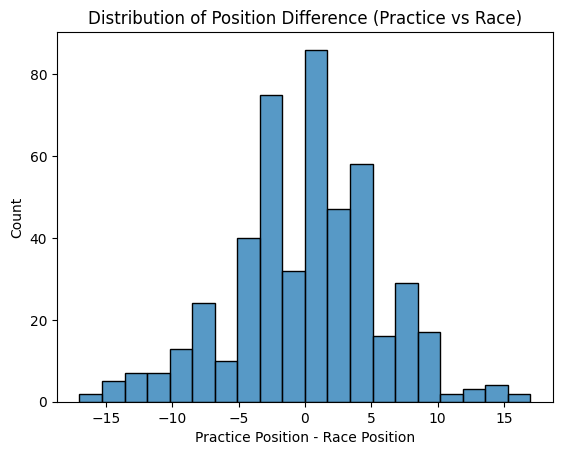

In [25]:
sns.histplot(f1_2024['PositionDifference'])
##Histogram of Position Differnece
plt.xlabel('Practice Position - Race Position')
plt.title('Distribution of Position Difference (Practice vs Race)')
##Labels and Titles
plt.show()

#### In the Histogram above the Position Difference is mapped to see distribution of differnece and visual noramlity
While the figure draws out a somewhat normal bell curve there are 2 bars that are quite shorter then they should be prompting a normaility check. 
<br><br><br>
Below is that test using a Shapiro-Wilk test

In [26]:
##Histogram looks semi-normal distrbuted so statically chekcing for that
data = f1_2024['PositionDifference'].dropna()
##Drop NA just in case
stat, p = shapiro(data)
##Shapiro Test based on data size to test for normal distribution
print(f"Shapiro-Wilk test statistic={stat}, p-value={p:}")
##Prints Statistics
alpha = 0.05
##Set significance levels
if p > alpha:
    print("Fail to reject H0: data likely follows normal distribution")
else:
    print("Reject H0: data is not normally distributed")

Shapiro-Wilk test statistic=0.9906863525068488, p-value=0.004058173191477291
Reject H0: data is not normally distributed


Here I have run a Shaprio-Wilk test on Position Differnce and found that the distribution is not normal. 
* While Our test-stat is very close to 1 suggesting normallity, 
* Our p-value is less the 0.05 meaning that this data is not normally ditrubuted and future test need to account for this

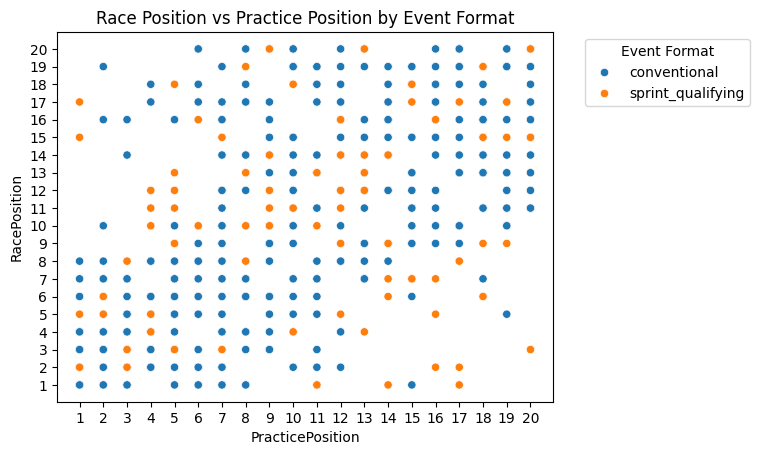

In [27]:
sns.scatterplot(data=f1_2024, x='PracticePosition', y='RacePosition', hue='EventFormat')
##ScatterPlot of Race vs Practice position
plt.legend(title='Event Format', bbox_to_anchor=(1.05, 1), loc='upper left')
##Move Legend to outside box
plt.xticks(range(1, 21))
plt.yticks(range(1, 21))
plt.title('Race Position vs Practice Position by Event Format')
##set title
plt.show()

#### In the Scatterplot above the Race Position is on the Y-axis and the X-axis is Predicted Practice Position
This figure was made to see if any clear patterns would appear that could further be explored. <br>
As is the case the graph is seemly near random with some weight to higher positions remaining higher and lower remaining lower. But no clear pattern is here to explore as this show quite a random picture. 
<br><br><br>
My next step from here was to split the scatter plot by round for further visualizations.

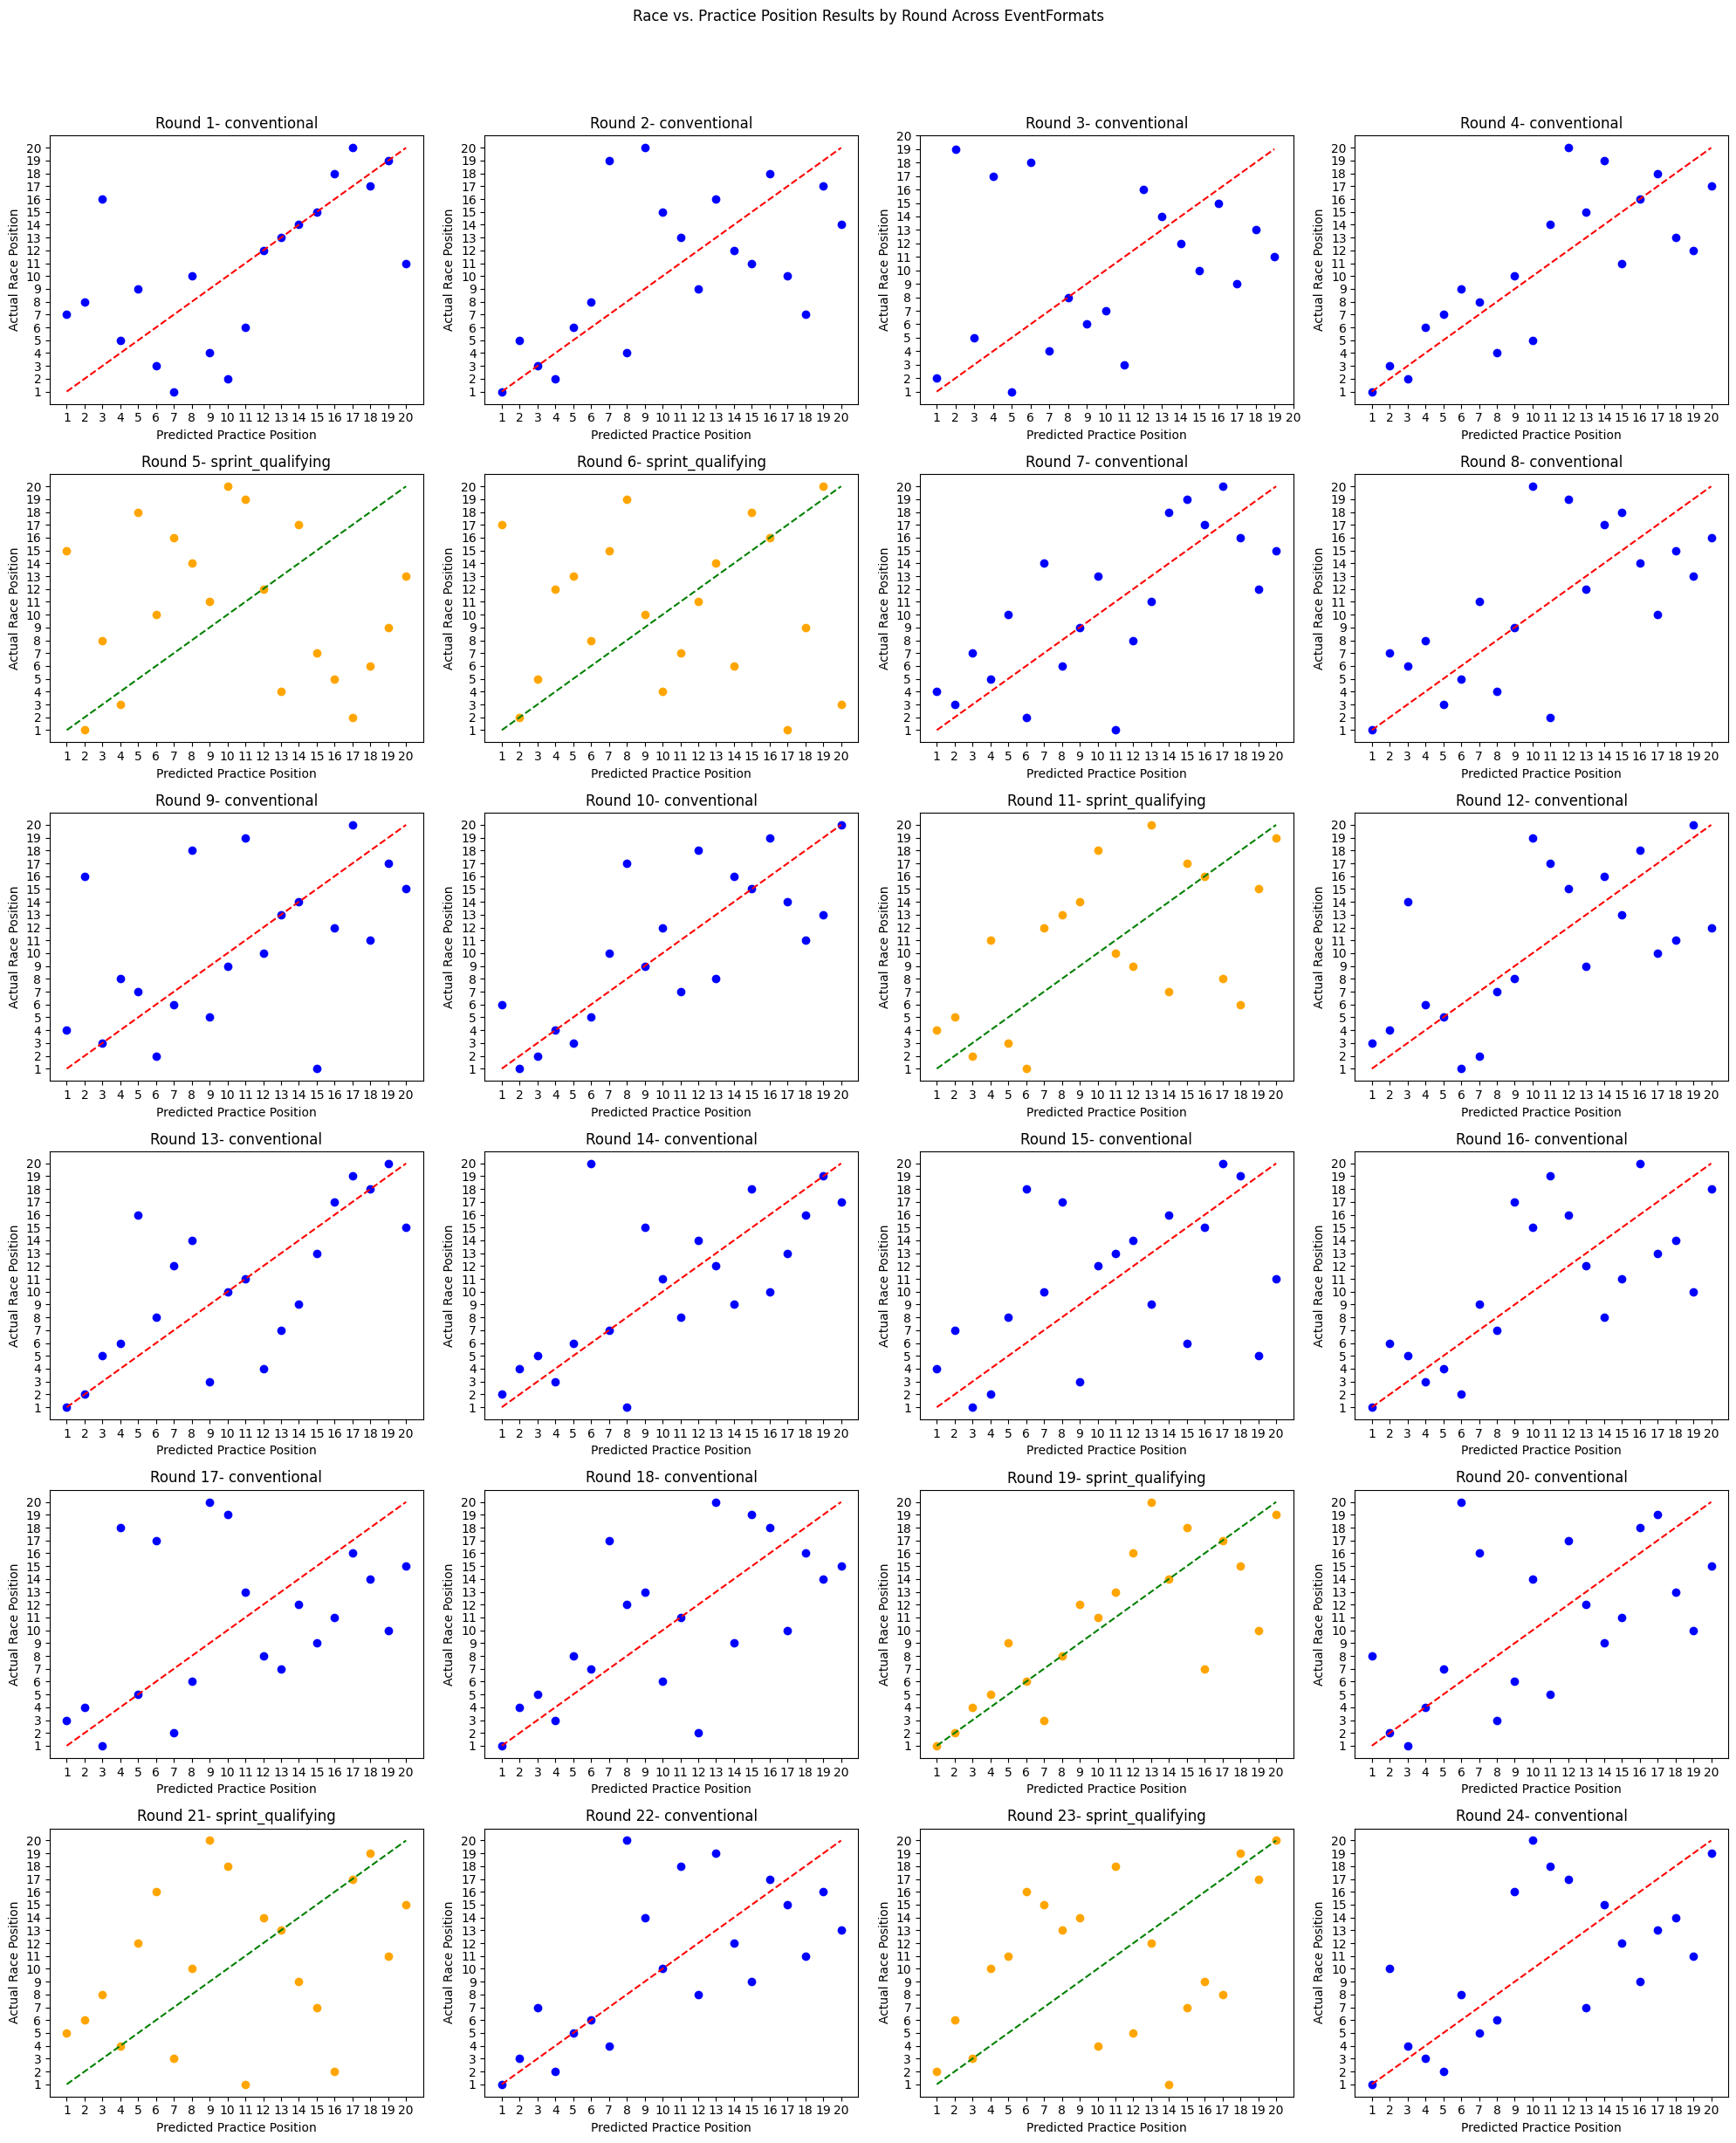

In [28]:
##Graph Individual rounds Scatterplots
unique_rounds = sorted(f1_2024['Round'].unique())
unique_event_formats = f1_2024['EventFormat'].unique()
##Get uniques and formats
fig, axes = plt.subplots(nrows=6, ncols=4, figsize=(20, 25))
##Create Subplots
axes = axes.flatten()
##Flatten for ease of use
color_map = {'sprint_qualifying': ('orange', 'green'),'conventional': ('blue', 'red')}
##Define Colors for Event Formats
for i, rnd in enumerate(unique_rounds):
##Loop though rounds
    ax = axes[i]
    ##Select Subplot for Round
    for evfmt in unique_event_formats:
    ##Plot data for each format
        round_data = f1_2024[(f1_2024['Round'] == rnd) & (f1_2024['EventFormat'] == evfmt)]
        ##Get only for this round and format
        if round_data.empty:
        ##Skip if no data
            continue
            
        x = round_data[['PracticePosition']]
        y = round_data['RacePosition']
        ##Varibles for plotting
        dot_color, line_color = color_map.get(evfmt, ('gray', 'gray'))
        ##Get colors for format/ Grey as catchall
        ax.scatter(x, y, color=dot_color, label=evfmt if i==0 else "")
        ##Create ScatterPlot
        ax.plot([y.min(), y.max()], [y.min(), y.max()], linestyle='--', color=line_color)
        ##Dashed line for reference if matched positions perfectly
        ax.set_title(f"Round {rnd}- {evfmt}")
        
    ax.set_xticks(range(1, 21))
    ax.set_yticks(range(1, 21))
    ax.set_xlabel('Predicted Practice Position')
    ax.set_ylabel('Actual Race Position')
    ##Set titles and labels

plt.suptitle('Race vs. Practice Position Results by Round Across EventFormats')
plt.tight_layout(rect=[0, 0, 1, 0.95])
##Leave Space at top for Suptitle
plt.show()

#### In these Scatterplots above the Race Position is on the Y-axis and the X-axis is Predicted Practice Position
This figure went round by round and mapped out each driver’s Race Vs Practice position. With Red/Blue representing the normal weekend and Green/orange representing the sprint weekends <br>
This shows a clearer picture of random compared to the pervious graph but still seems random with a general upward trend. No visual difference for each weekend type is seen. 
<br><br><br>
My next step from here was to split the scatter plot by driver.

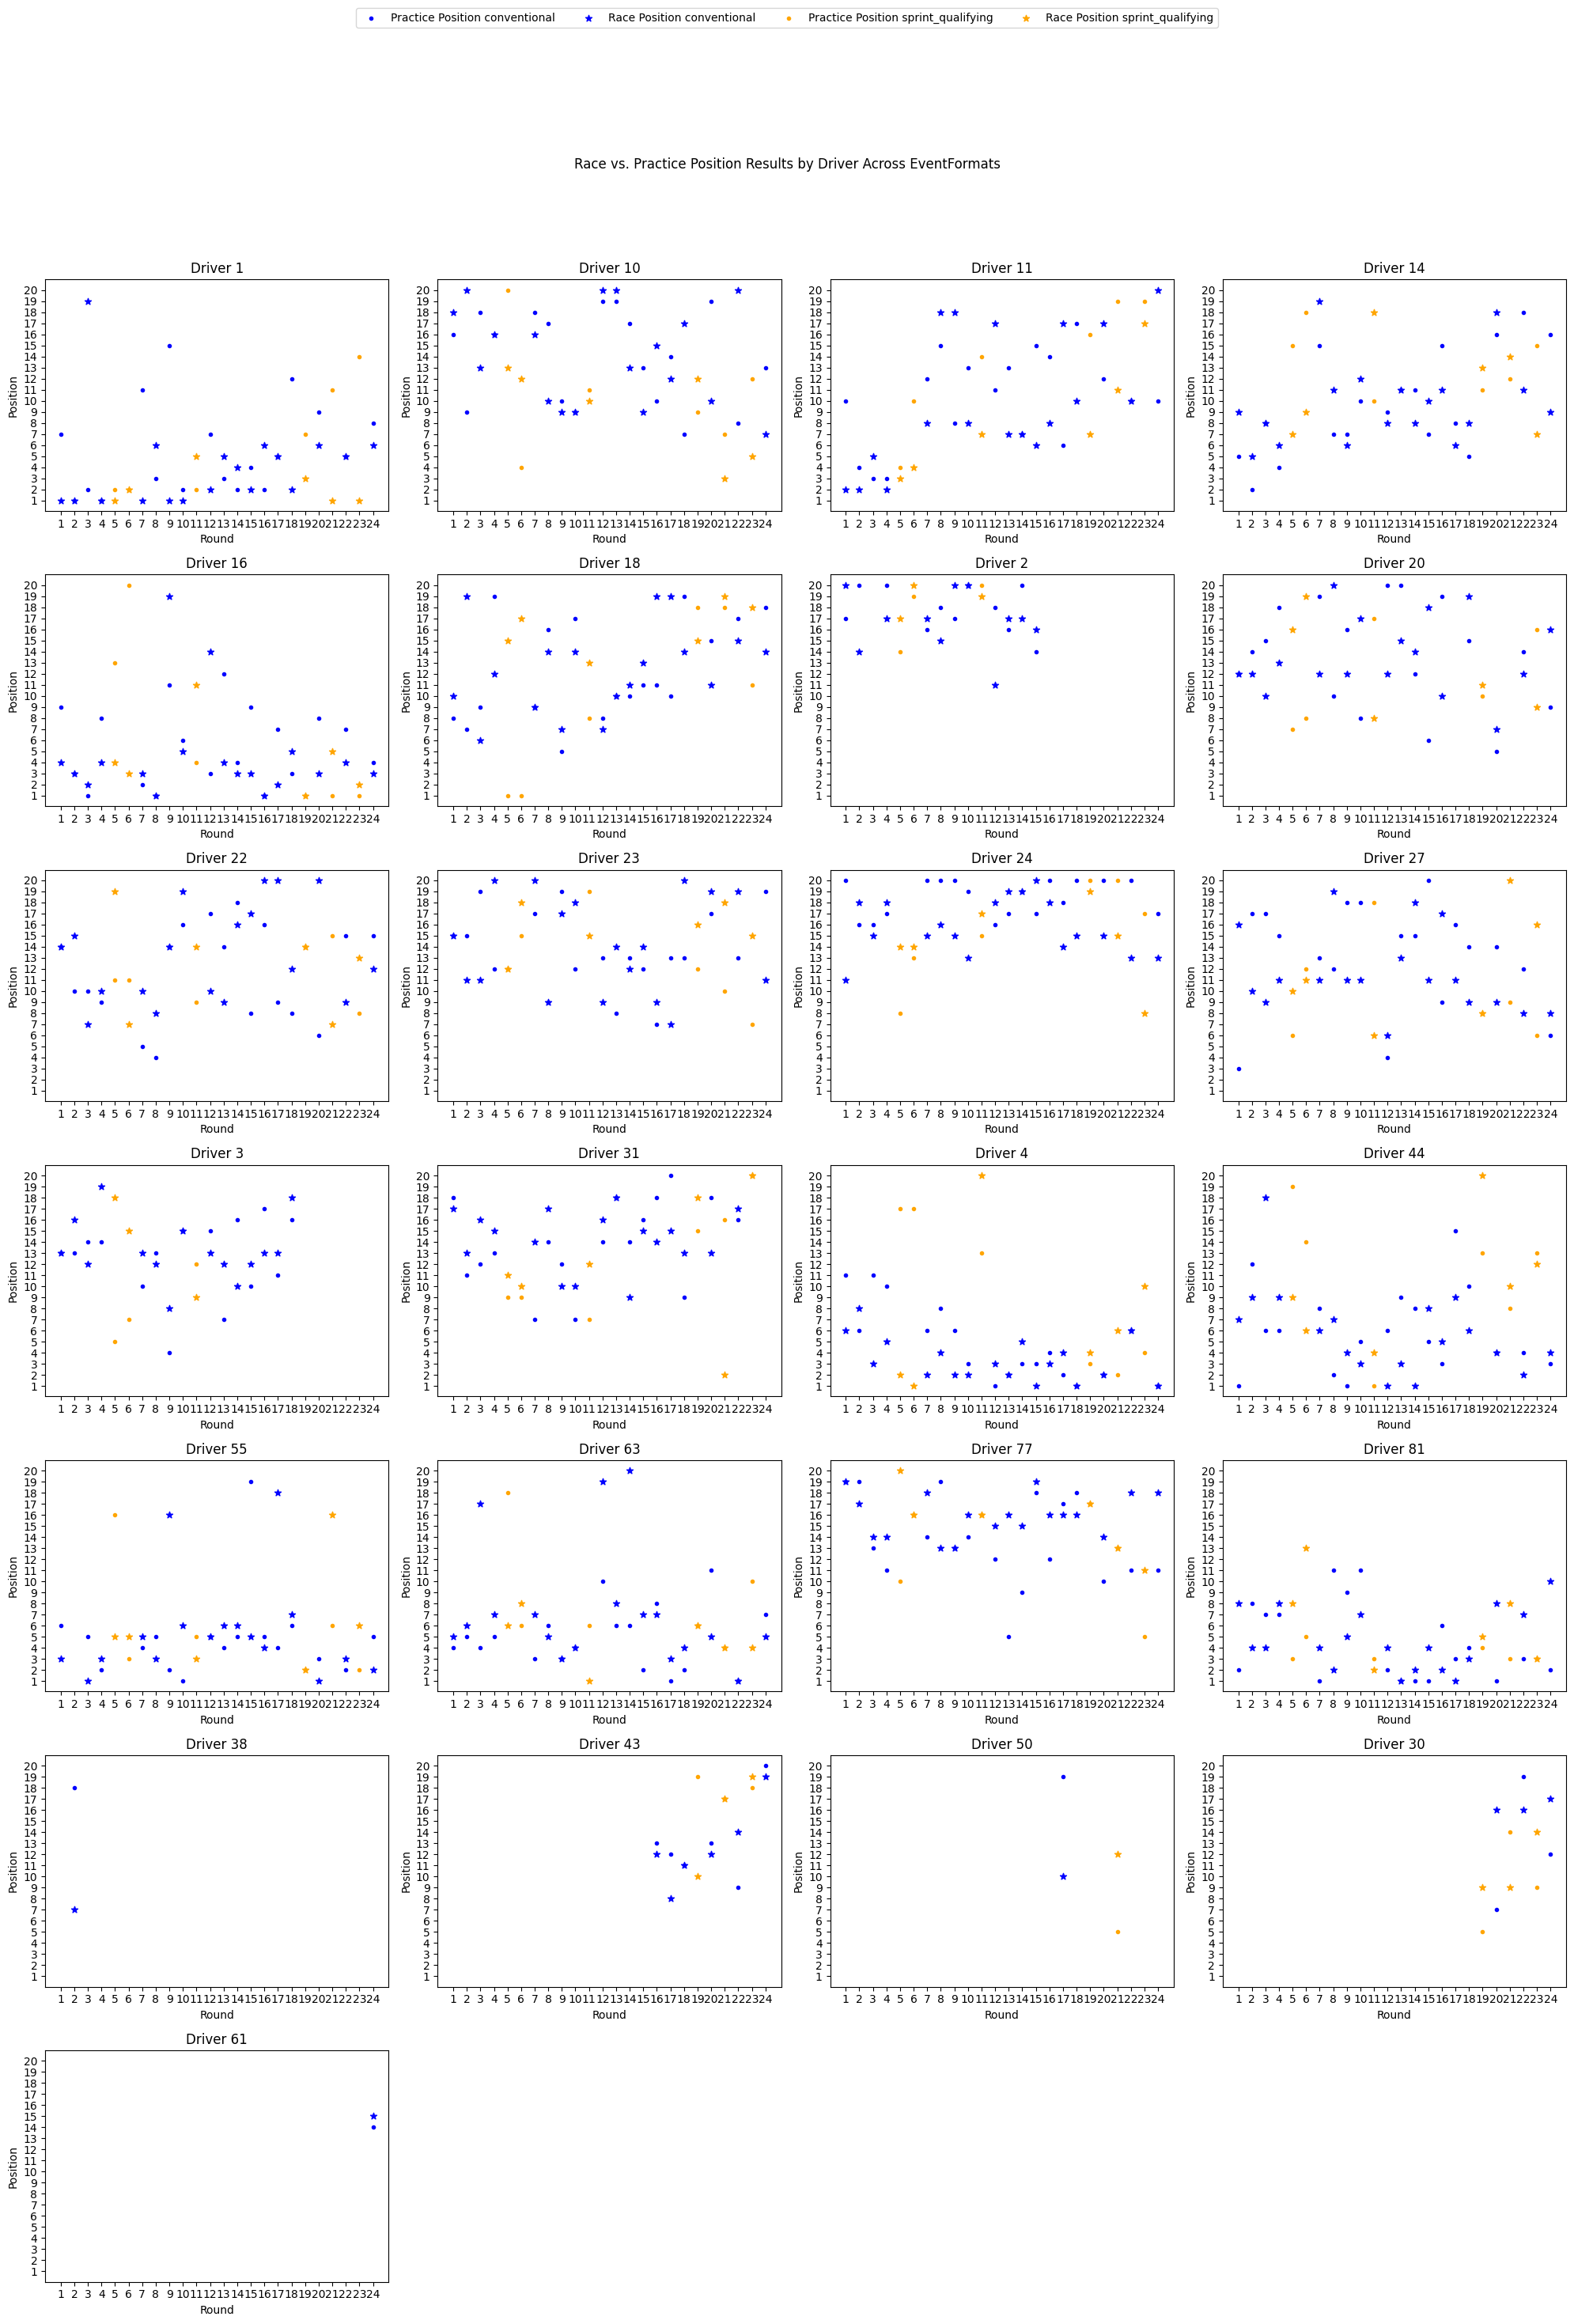

In [29]:
##Graph Indivdual Diver Scatterplots
drivers = f1_2024['DriverNumber'].unique()
##Get Dirver List
num_drivers = len(drivers)
##Get Number of Drivers
cols = 4
rows = (num_drivers + cols - 1) // cols
##Get Grid Size to be 4, (num_drivers + cols - 1) // cols
color_map = {'sprint_qualifying': 'orange', 'conventional': 'blue'}
##Set colors for event
fig, axes = plt.subplots(rows, cols, figsize=(20, rows * 4), sharex=True, sharey=True)
##Create figure/ grid
axes = axes.flatten()  
##Flatten for ease of use
for i, driver in enumerate(drivers):
##For Each driver
    ax = axes[i]
    ##Set Subplot
    driver_df = f1_2024[f1_2024['DriverNumber'] == driver]
    ##grab Driver
    for event_format in driver_df['EventFormat'].unique():
        ##Loop over both events for driver
        df_subset = driver_df[driver_df['EventFormat'] == event_format]
        ##Grab event type
        color = color_map.get(event_format, 'gray')
        ##Set default color just in case
        ax.scatter(df_subset['Round'], df_subset['PracticePosition'], label=f'Practice Position {event_format}', marker='.', color=color)
        ax.scatter(df_subset['Round'], df_subset['RacePosition'], label=f'Race Position {event_format}', marker='*', color=color)
        ##Create Scatter plot for race and proactice position with color and markers      
    ax.set_title(f'Driver {driver}')
    ##Set Title with Driver
    
    ax.set_xticks(range(1, 25))
    ax.set_yticks(range(1, 21))
    ax.tick_params(axis='x', labelbottom=True)
    ax.tick_params(axis='y', labelleft=True)
    ax.set_xlabel('Round')
    ax.set_ylabel('Position')
    ##Set Ticks

for j in range(i + 1, len(axes)):
    ##Remove empty subplots if any
    fig.delaxes(axes[j])
    
handles, labels = axes[0].get_legend_handles_labels() 
##get handles and labels from first subplot
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.05), ncol=4)
##Move Legend to outside box
plt.suptitle('Race vs. Practice Position Results by Driver Across EventFormats')
##Set Title
plt.tight_layout(rect=[0, 0, 1, 0.95])
##Give space to totle and legend to top of graph
plt.show()

#### In these Scatterplots above the Position is on the Y-axis and the X-axis is Round
This figure went round by round and mapped out each driver’s Position, Predicted are a circle and Race position with a star <br>
This shows another picture of random. Here there is a general trend in a certain area for each driver that is due to their skill and car performance. But what this shows us while looking at the circles and stars there are no visual patterns for that of the Sprint weekends (Orange) and conventional weekends (Blue)
<br><br><br>
My next step from here was run a linear regression to get a mean-squared area, and r^2 values. 

In [30]:
features = ['PracticePosition']
x = f1_2024[features].dropna()
y = f1_2024.loc[x.index, 'RacePosition']
##Grab features and target
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
##Split and train data
model = LinearRegression()
model.fit(x_train, y_train)
##Fit model
y_pred = model.predict(x_test)
##Predict
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2:", r2_score(y_test, y_pred))

MSE: 26.44381851425001
R2: 0.26259567121949057


Here I used a Linear Regression model to find the mean squared error and R^2 values to hopefully find some insights into the data.
* Our Mean-Squared Error is 26.44 meaning the average error between our predicted race position and actual race position are around (square root of 26.44 =) 5.14 units apart

* The r^2 valued at 0.26 means 26% of the variation is explained and most of the variation is unexplained

* Meaning our use of practice position is not a strong fit but a more modest effect in predicting race positions

<br><br><br>
From this point I have decided to create a strip plot to the visual difference from practice and race position in a clearer manner

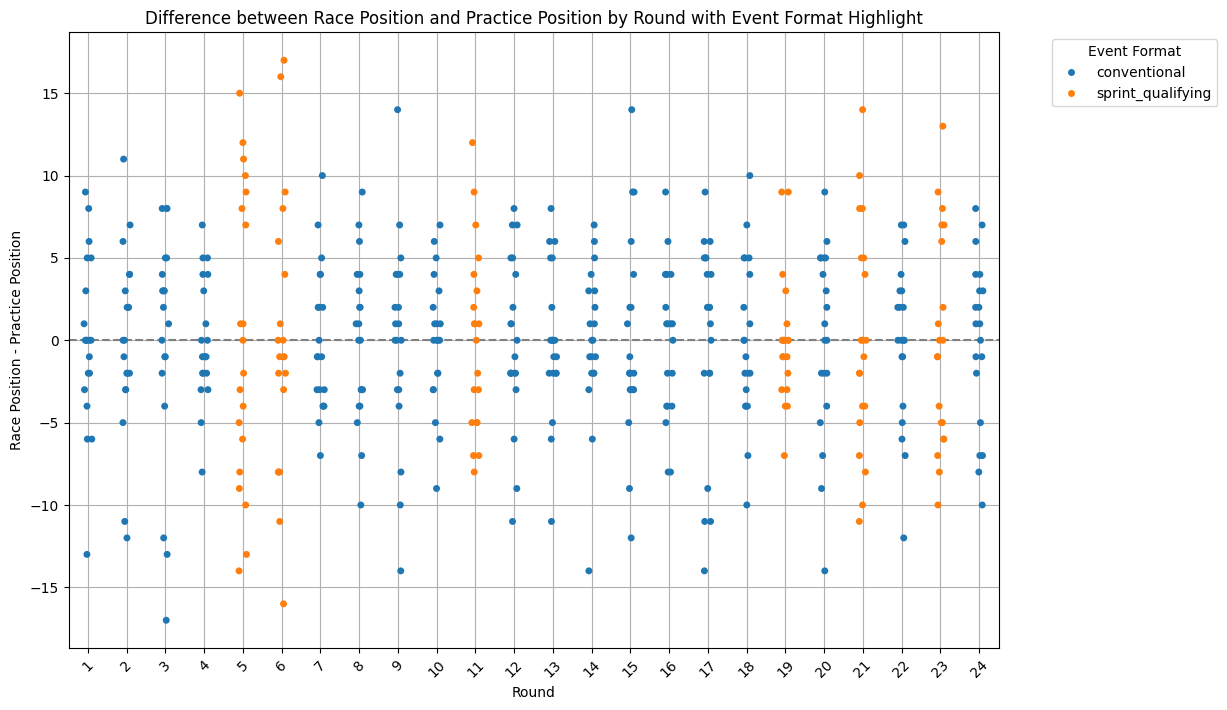

In [31]:
plt.figure(figsize=(12, 8))
##Set Figure
sns.stripplot(data=f1_2024, x='Round', y='PositionDifference', jitter=True, hue='EventFormat', palette='tab10')
##Create Stripplot
plt.axhline(0, color='gray', linestyle='--')  
plt.legend(title='Event Format', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.title('Difference between Race Position and Practice Position by Round with Event Format Highlight')
plt.xlabel('Round')
plt.ylabel('Race Position - Practice Position')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

#### In this StripPlot above the Position Difference between Race and Practice is on the Y-axis and the X-axis is on Round
This figure went round by round and mapped out each Driver for difference between their Practice and race position. The Blue dots are for conventional weekends, and the orange are for sprint weekends. <br>
This shows another picture of random. The general spread of the data seems to show again no pattern with distributions being random
<br><br><br>
My next step from here was map out if Best Practice lap could show any trend in the data. 

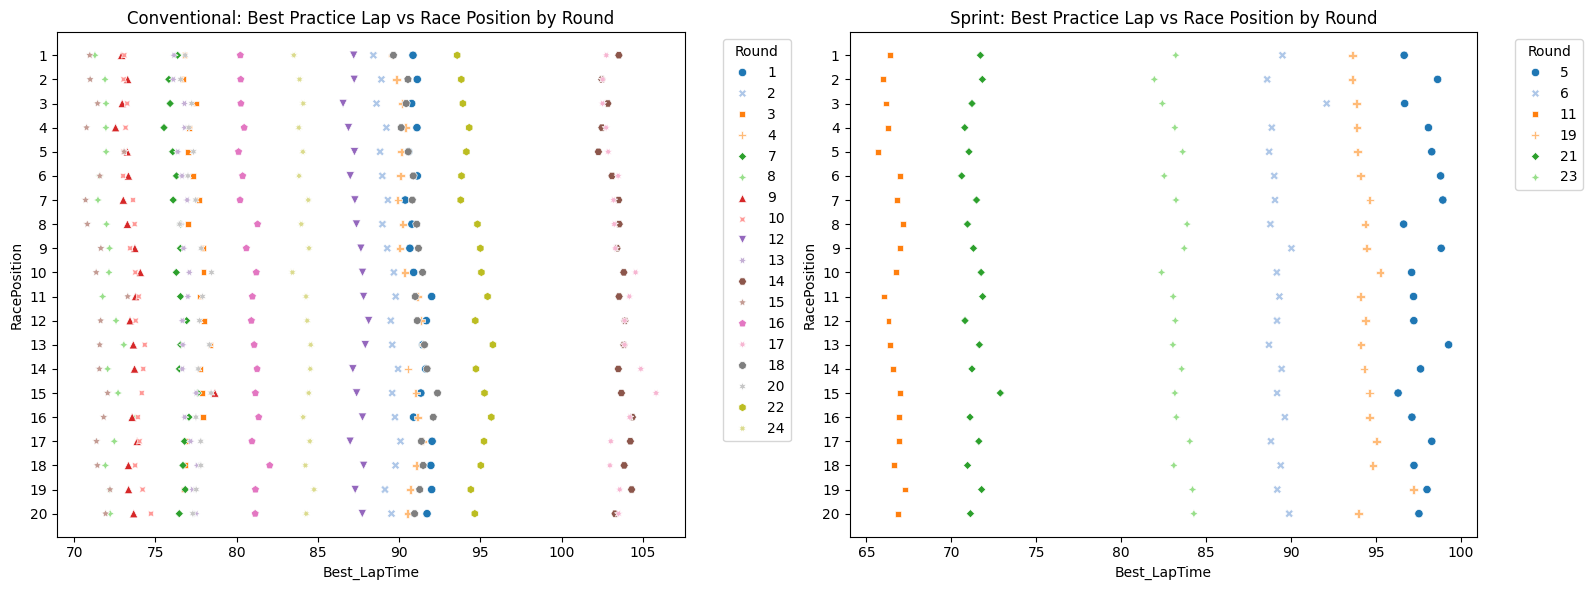

In [32]:
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))
##Set figure

sns.scatterplot(data=conventional_df, x='Best_LapTime', y='RacePosition', hue='Round', style='Round', palette='tab20', ax=ax1)
ax1.set_title('Conventional: Best Practice Lap vs Race Position by Round')
ax1.set_yticks(range(1, 21))
ax1.set_yticklabels([str(i) for i in range(1, 21)])
ax1.legend(title='Round', bbox_to_anchor=(1.05, 1), loc='upper left')
# Plot for conventional weekends

ax1.set_ylim(ax1.get_ylim()[::-1]) 
##Invert y-axis 

sns.scatterplot(data=sprint_df, x='Best_LapTime', y='RacePosition', hue='Round', style='Round', palette='tab20', ax=ax2)
ax2.set_title('Sprint: Best Practice Lap vs Race Position by Round')
ax2.set_yticks(range(1, 21))
ax2.set_yticklabels([str(i) for i in range(1, 21)])
ax2.legend(title='Round', bbox_to_anchor=(1.05, 1), loc='upper left')
##Plot for sprint weekends

ax2.set_ylim(ax2.get_ylim()[::-1])
##Invert y-axis 
plt.tight_layout()
plt.show()

#### In this Scatterplot above the Race Positions on the Y-axis and the X-axis is on Best Lap Time
This figure was made to show if any pattern could be found within Lap Time and race position. What it shows us is another picture of random. Each dot is a driver’s best time in practice and their position in the final race. While I was hoping for a pattern to draw from, I found another set of random data points.
<br><br><br>
My next step from here was to create a Heatmap between several variables in hopes to find a correlation to inspect further.

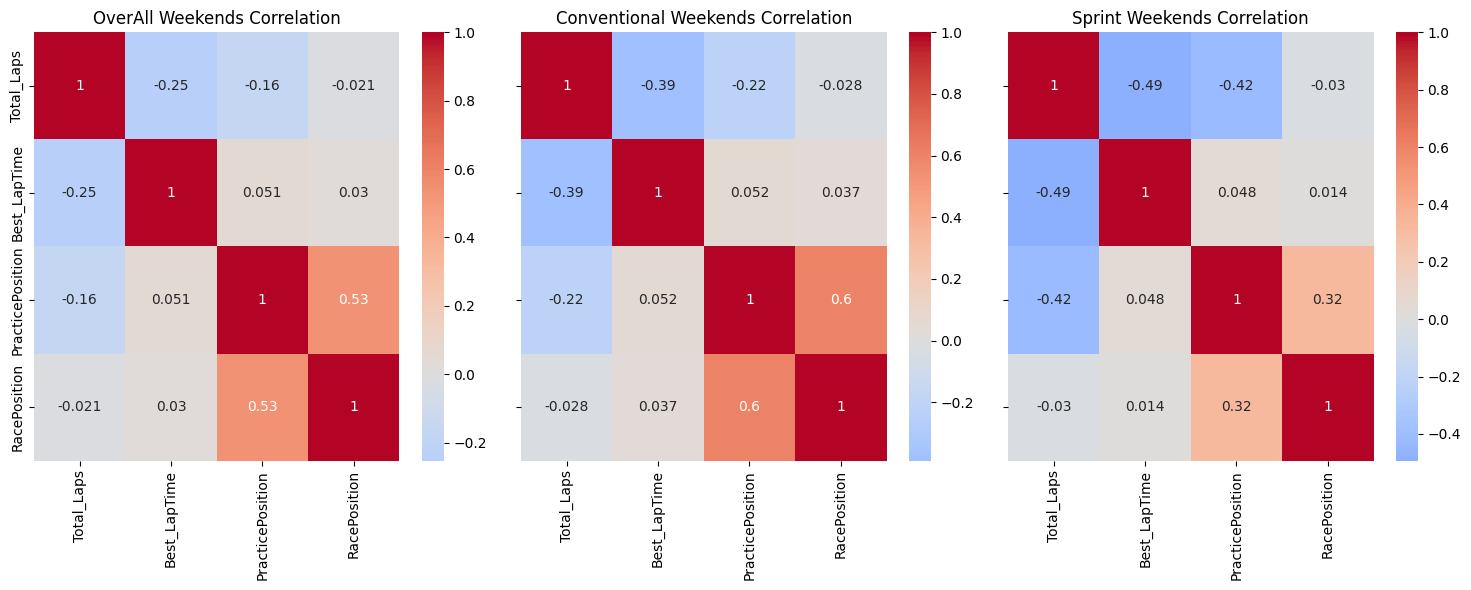

In [33]:
cols_to_corr = ['Total_Laps', 'Best_LapTime', 'PracticePosition', 'RacePosition']
##Set Correlation Values
conventional_corr = conventional_df[cols_to_corr].corr()
sprint_corr = sprint_df[cols_to_corr].corr()
overall_corr = f1_2024[cols_to_corr].corr()
##Correlate on All weekends, sprint and conventional 
fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)
##Create Figure
sns.heatmap(overall_corr, annot=True, cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("OverAll Weekends Correlation")
##Plot heatmap for overall weekends on the first subplot
sns.heatmap(conventional_corr, annot=True, cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Conventional Weekends Correlation")
##Plot heatmap for conventional weekends on the second subplot
sns.heatmap(sprint_corr, annot=True, cmap="coolwarm", center=0, ax=axes[2])
axes[2].set_title("Sprint Weekends Correlation")
##Plot heatmap for sprint weekends on the third subplot
plt.tight_layout()
plt.show()

#### In the Heatmap above the Total Laps, Best Lap Time, Practice Position, and Race Position correlation is mapped
The only 2 values that seem to have any correlation is Practice Position and Race Position.
This is told us that our normalized Practice Position that was predicted is an indicator of Race position but the values use to predicted the Practice Position, Total Laps and Best Lap time, don't hold any correlation to our final race position.
<br><br><br>
Below is a Spearman Test on that correlation for both weekend types. 

In [34]:
correlation_o, p_value_o = stats.spearmanr(f1_2024['PracticePosition'], f1_2024['RacePosition'])
correlation_c, p_value_c = stats.spearmanr(conventional_df['PracticePosition'], conventional_df['RacePosition'])
correlation_s, p_value_s = stats.spearmanr(sprint_df['PracticePosition'], sprint_df['RacePosition'])
##Run spearman rank correlation test
print(f"--------Overall Weekends--------")
print(f"Spearman correlation: {correlation_o}")
print(f"P-value: {p_value_o}")
##Print Stats
alpha = 0.05
##Set significance  
if p_value_o > alpha:
    print("Fail to reject H0: data likely follows normal distribution")
else:
    print("Reject H0: data is unlikly correlated due to chance")
    
print(f"--------Conventional Weekends--------")
print(f"Spearman correlation: {correlation_c}")
print(f"P-value: {p_value_c}")
##Print Stats
##Set significance  
if p_value_c > alpha:
    print("Fail to reject H0: data likely follows normal distribution")
else:
    print("Reject H0: data is unlikly correlated due to chance")

print(f"--------Sprint Weekends--------")
print(f"Spearman correlation: {correlation_s}")
print(f"P-value: {p_value_s}")
##Print Stats
##Set significance  
if p_value_s > alpha:
    print("Fail to reject H0: data likely follows normal distribution")
else:
    print("Reject H0: data is unlikly correlated due to chance")

--------Overall Weekends--------
Spearman correlation: 0.5339659287417666
P-value: 1.1677689773208348e-36
Reject H0: data is unlikly correlated due to chance
--------Conventional Weekends--------
Spearman correlation: 0.6046893868807879
P-value: 3.609965104252121e-37
Reject H0: data is unlikly correlated due to chance
--------Sprint Weekends--------
Spearman correlation: 0.32355889724310777
P-value: 0.0003124170310112785
Reject H0: data is unlikly correlated due to chance


Above is the Spearman test on the data. It shows that we have found a strong liklyhood that Practice and Race positions due in fact have a correlation.
* On Overall Weekends we have a strong correlation between Practice and Race Position and a P-values lower then 0.5
* On Conventional Weekends we have a strong correlation between Practice and Race Position and a P-values lower then 0.5
* On Sprint Weekends we have a moderate correlation between Practice and Race Position and a P-values lower then 0.5

In [35]:
model = smf.mixedlm("RacePosition ~ PracticePosition + Total_Laps +  Best_LapTime+ EventFormat", data=f1_2024, groups=f1_2024["DriverNumber"])
##Mixed-Effects Modeling 

result = model.fit()
print(result.summary())

                  Mixed Linear Model Regression Results
Model:                  MixedLM      Dependent Variable:      RacePosition
No. Observations:       479          Method:                  REML        
No. Groups:             25           Scale:                   16.3641     
Min. group size:        1            Log-Likelihood:          -1385.4424  
Max. group size:        24           Converged:               Yes         
Mean group size:        19.2                                              
--------------------------------------------------------------------------
                                 Coef.  Std.Err.   z   P>|z| [0.025 0.975]
--------------------------------------------------------------------------
Intercept                         7.943    2.328 3.412 0.001  3.381 12.505
EventFormat[T.sprint_qualifying]  0.282    0.631 0.446 0.655 -0.955  1.518
PracticePosition                  0.179    0.046 3.860 0.000  0.088  0.270
Total_Laps                        0.010    0

This Mixed Effect modeling test helps to indicate what is and what isn't a strong predictor of Race Position.

* The intercept on this test is 7.943 and this indicates that expected race position when all other predictors are 0 is hypothetically 7.9
* Event Format, Sprint Qualifying has a 0.282 coefficient and a p-value of 0.655 meaning that event format has a non-significant effect on race vs a conventional weekend
* The Practice Position has a significant value (p-value <0.001) and a positive coefficient meaning as Practice position gets worse Race position gets worse as well
* Total Laps and Best Lap Time have a very low coefficient and a non-significant p-value meaning that neither value explains race position
* And the group variance is 11.558 which makes sense as all drivers have different skills and car performance

### In Conclusion, the practice Position Algorithm is an indicator of final positioning in a race 
### But Sprint vs Conventional Weekends do not have a significant difference
### Meaning that even with less practice on average the drivers will not see significant impact on the race day 